In [1]:
import os
import pandas as pd
import datajoint as dj
# from datetime import datenid
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import zscore

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\_distributor_init.py:32: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.PYQHXLVVQ7VESDPUVUADXEVJOBGHJPAY.gfortran-win_amd64.dll
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.XWYDX2IKJW2NMTWSFYNGFUWKQU3LYTCZ.gfortran-win_amd64.dll
  stacklevel=1)


In [2]:
dj.config['database.host'] = '10.38.76.219'
dj.config['database.user'] = 'root'
dj.config['database.password'] = 'retina'
dj.config["enable_python_native_blobs"] = True # Only for testing in dj0.12 (https://github.com/datajoint/datajoint-python#python-native-blobs)
os.chdir('../..')

%env DJ_SUPPORT_FILEPATH_MANAGEMENT=TRUE
import main 
drive_path = r"V:\Data\datajoint\DJEphys"
data_path = r"T:\Data"

ft = main.load(drive_path, data_path)

env: DJ_SUPPORT_FILEPATH_MANAGEMENT=TRUE
Connecting root@10.38.76.219:3306


In [3]:
import configs
from ephys import utils
from analysis import depth_estimation

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numba\core\types\__init__.py:108: DeprecationWarning: `np.long` is a deprecated alias for `np.compat.long`. To silence this warning, use `np.compat.long` by itself. In the likely event your code does not need to work on Python 2 you can use the builtin `int` for which `np.compat.long` is itself an alias. Doing this will not modify any behaviour and is safe. When replacing `np.long`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  long_ = _make_signed(np.long)
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numba\core\types\__init__.py:109: DeprecationWarning: `np.long` is a deprecated alias for `np.compat.long`. To silence this warning, use `np.compat.long` by itself. In the li

In [4]:
exp_table = ft.Experiment()
sess_table = ft.Session()
mouse_table = ft.Mouse()
subsess_table = ft.Subsession()
raw_table = ft.ephys_tables.EphysRaw()
raw_helper_table = ft.ephys_tables.EphysRawHelper()
events_table = ft.event_tables.SubsessionEvents()
sess_split_table = ft.SessionSplit() 
sorted_table = ft.ephys_tables.SpikeSorted()
metrics_table = ft.ephys_tables.ClusterMetrics()
subsess_spikes_table = ft.ephys_tables.SubsessionSpikes()
trials_table = ft.ephys_tables.TrialSpikes()
opto_table = ft.ephys_tables.OptoTagging()
opto_cluster_table = ft.ephys_tables.OptoCluster()
cluster_table = ft.ephys_tables.Cluster()
opto_clustering_table = ft.ephys_tables.OptoClusterClustering()
cluster_trials_table = ft.ephys_tables.ClusterTrial()
behavior_table = ft.behavior_tables.Behavioral()
behavior_trials_table = ft.behavior_tables.TrialBehavioral()
cluster_sweep_metrics_table = ft.ephys_analysis_tables.ClusterSweepMetrics()
cluster_loom_metrics_table = ft.ephys_analysis_tables.ClusterLoomMetrics()
cluster_depth_table = ft.ephys_tables.ClusterDepth()
clustering_table = ft.ephys_analysis_tables.VisualClustering()
cluster_clustering_table = ft.ephys_analysis_tables.ClusterClustering()

### Things to go through
- Depth estimation based on histology and CSD during RFM
- Visual responses of neurons in AOI
- Optotagged neurons in the AOI (if available)
- Before / after chemogenetic manipulation of neurons in AOI (if available)

In [5]:
def visualize_CSD(LFP, CSD, depths, channels, sub_start=10000, sub_end=13000, hlines=None):
    # LFP: (n_channels, time) ; CSD: (n_channels, time)
    CSD_n_channels = len(channels)-2
    CSD_depths = depths[1:-1]
    LFP = LFP[1:-1] # Remove the first and last channel to match CSD channels
    print(CSD_n_channels, len(CSD_depths), CSD.shape)

    mean_CSD = np.mean(CSD[:,sub_start:sub_end], axis=1)
    zero_crossing = np.argmin(np.abs(mean_CSD[:]))

    fig, axs = plt.subplots(2, 2, figsize=(12, 7))
    print(LFP.shape, CSD.shape)
    sb.heatmap(LFP, cmap='Greys', ax=axs[0,0], center=0)
    # axs[0,0].set(yticks=np.arange(0, len(channels))[::40], yticklabels=depths[::40].astype('int16'), xticks=np.arange(0, 20000, 2500)+1, xticklabels=(np.arange(0, 20000, 2500)/2500).astype('int16')+1, title='LFP - baseline', ylabel='distance from tip (um)')
    axs[0,0].invert_yaxis()
    axs[0,0].tick_params(axis='x', labelrotation = 0)
    axs[0,0].set(yticks=np.arange(0, len(channels)), yticklabels=depths.astype('int16'), xticks=np.arange(0, 20000, 2500)+1, xticklabels=(np.arange(0, 20000, 2500)/2500).astype('int16')+1, title='LFP - baseline', ylabel='distance from tip (um)')
    axs[0,0].yaxis.set_major_locator(plt.MultipleLocator(5))
    axs[0,0].yaxis.set_minor_locator(plt.MultipleLocator(1))
    axs[0,0].tick_params(axis='y', which='both', left=True)
    
    sb.heatmap(CSD, cmap='vlag', ax=axs[0,1], center=0)
    axs[0,1].set(yticks=np.arange(0, CSD_n_channels)[::40], yticklabels=CSD_depths[::40].astype('int16'), xticks=np.arange(0, 20000, 2500)+1, xticklabels=(np.arange(0, 20000, 2500)/2500).astype('int16')+1, title='CSD', ylabel='distance from tip (um)')
    # plt.imshow(CSD, extent=(0, 6, 0, 4), cmap='Greys')
    axs[0,1].invert_yaxis()
    axs[0,1].tick_params(axis='x', labelrotation = 0)
    axs[0,1].axhline(zero_crossing, c='r', linestyle='--', linewidth=0.5)

    # sb.heatmap(signals_mean[::-1], cm9635418000]), extent=(0, 6, 0, 4), cmap='Greys')
    sb.heatmap(CSD[:,sub_start:sub_end], cmap='vlag', ax=axs[1,0], center=0)
    # axs[1,0].imshow(np.abs(CSD[:,12000:18000]), extent=(0, 6, 0, 4), cmap='Greys')
    axs[1,0].set(yticks=np.arange(0, CSD_n_channels)[::40], yticklabels=CSD_depths[::40].astype('int16'), xticks=np.arange(0, sub_end-sub_start+1, 2500), xticklabels=(np.arange(sub_start, sub_end+1, 2500)/2500), title='CSD', ylabel='distance from tip (um)')
    axs[1,0].invert_yaxis()
    axs[1,0].tick_params(axis='x', labelrotation = 0)
    axs[1,0].axhline(zero_crossing, c='r', linestyle='--', linewidth=0.5)
   
    axs[1,1].plot(mean_CSD)
    axs[1,1].axvline(zero_crossing, c='r')
    axs[1,1].set(title=f'mean CSD ~ {CSD_depths[zero_crossing]}', xticks=np.arange(0, CSD_n_channels)[::40], xticklabels=CSD_depths[::40].astype('int16'), xlabel='distance from tip (um)')
    axs[1,1].tick_params(axis='x', labelrotation = 90)
    axs[1,1].axhline(0, linestyle='--', linewidth=0.5, c='k')
    print(zero_crossing)
    if hlines is not None:
        for hline in hlines:
            print("Showing hlines", hline)
            # hline_converted = ((hline//2)//10)-2
            hline_converted = np.argmin(np.abs(CSD_depths-hline))
            axs[0,0].axhline(hline_converted, c='b', linewidth=0.5, linestyle='--')
            axs[1,0].axhline(hline_converted, c='b', linewidth=0.5, linestyle='--')
            axs[0,1].axhline(hline_converted, c='b', linewidth=0.5, linestyle='--')
            axs[1,1].axvline(hline_converted, c='b', linewidth=0.5, linestyle='--')
    plt.tight_layout()
    # fig.canvas.draw_idle()
    plt.show()
    return CSD_depths[zero_crossing]

In [7]:
key = (sorted_table & {'experiment_id': '02357', 'mouse_id': '667LR', 'session_id': '20240909', 'session_split': 'full'}).fetch1("KEY")


S:\Data\02357\neuropixels\667LR\20240909\ephys\raw\02357_667LR_20240909_01_g0
10
Detected shanks: [1, 2]
(510000, 96)
94 94 (94, 30000)
(94, 30000) (94, 30000)
5
Showing hlines 200
Showing hlines -250


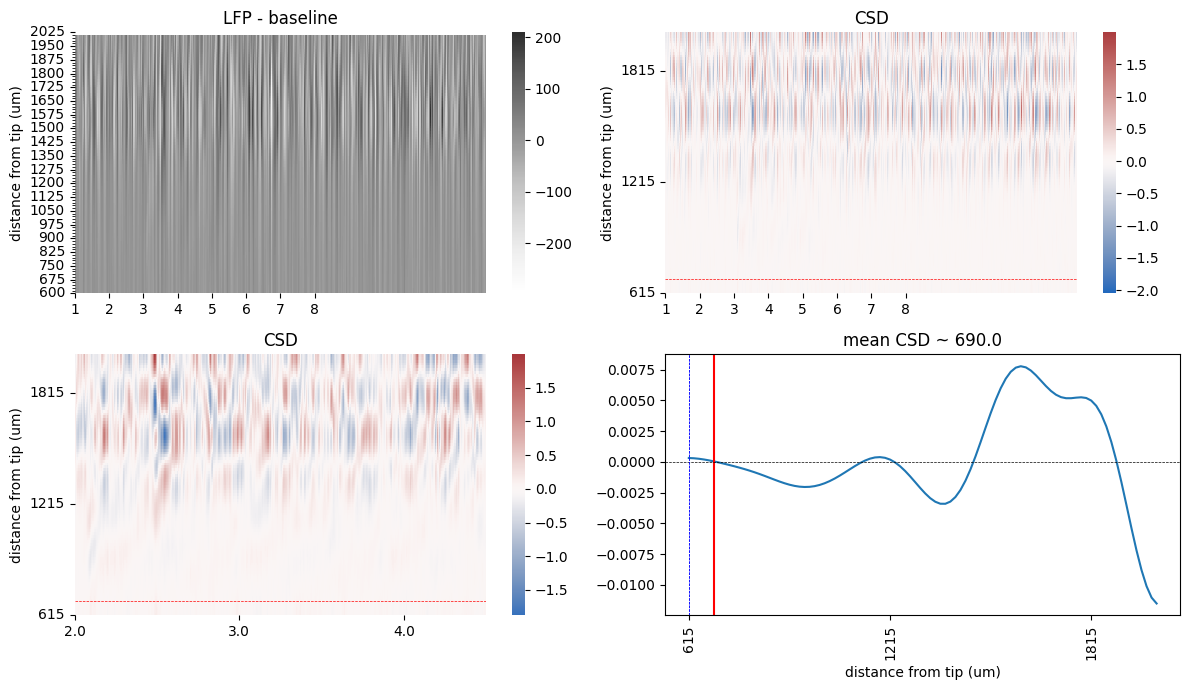

In [ ]:
# key = {'experiment_id': '02030', 'mouse_id': '255L', 'session_id': '20230720'}
# key = {'experiment_id': '02043', 'mouse_id': '252R', 'session_id': '20230724'}
# key = (sorted_table & {'experiment_id': '02030', 'mouse_id': '255L', 'session_id': '20230720', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02368', 'mouse_id': '464L', 'session_id': '20240820'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02368', 'mouse_id': '464L', 'session_id': '20240820'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02045', 'mouse_id': '107LR', 'session_id': '20230823', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02412', 'mouse_id': '610LL', 'session_id': '20250507', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02357', 'mouse_id': '667LR', 'session_id': '20240909', 'session_split': 'full'}).fetch1("KEY")
key = (sorted_table & {'experiment_id': '02034', 'mouse_id': '83L', 'session_id': '20230705', 'session_split': 'full'}).fetch1("KEY")

subsession_id = '01'
key['subsession_id'] = subsession_id
stim_type = 'EXPA'
shank = 1

# Load paths
vis_subsess_id = (subsess_table & key & {'subsession_type': 'VIS'}).fetch('subsession_id', order_by='subsession_idx')[0]
lfp_file = (raw_table & key & {'subsession_id': vis_subsess_id}).fetch('lfp_path')[0] # Take from first VIS path
server = (exp_table & key).fetch1('server')
server_local = configs.get_server_path(server, user='Bram')
session_path = os.path.join(server_local, key['experiment_id'], "neuropixels", key['mouse_id'], key['session_id'])
lfp_folder_path = utils.get_raw_folder_path(session_path, vis_subsess_id)
print(lfp_folder_path)
meta_files = [f for f in os.listdir(lfp_folder_path) if 'ap.meta' in f]#[0]
if len(meta_files) == 0:
    lfp_folder_path = [os.path.join(lfp_folder_path, folder) for folder in os.listdir(lfp_folder_path)][0]
meta_file = [f for f in os.listdir(lfp_folder_path) if 'ap.meta' in f][0]
rec_with_probe = depth_estimation.load_recording(lfp_folder_path, lfp_file, meta_file)

if 'RFM' in subsession_id:
    rfm_events_table = ft.event_tables.SubsessionEvents.RFMEvents()
    RFM_time = (rfm_events_table & key).fetch1('rfm_events')[0] # Select from 0th RFM frame (arbitrary pick)
    RFM_time = RFM_time/30000 - 10 # Convert to seconds
    data_mat, channels, depths = depth_estimation.get_RFM_data(RFM_time, rec_with_probe, shank=shank)
else:
    stim_events_table = ft.event_tables.SubsessionEvents.StimEvents()
    stim_times, stim_types = (stim_events_table & key).fetch1('stim_events', 'stim_types')
    stim_times = np.array(stim_times)/30000 # Convert to seconds
    stim_types = np.array(stim_types)
    stim_times = stim_times[stim_types == stim_type]
    print(len(stim_times))
    data_mat, channels, depths = depth_estimation.get_VIS_data(stim_times, rec_with_probe, shank=shank)

sf = rec_with_probe.get_sampling_frequency()
# Preprocess -> Bandpass filter data 1-100Hz
data_preproc = depth_estimation.preprocess_data(data_mat, bandpass=[1,100], sf=sf)

# Calculate CSD
data_preproc2, CSD = depth_estimation.calc_CSD(data_preproc)
data_preproc2 = data_preproc2[2500*5:]
CSD = CSD[2500*5:]

# Estimate depth based on CSD
window_start, window_end = 2,4.5
window_start, window_end = int(window_start*2500), int(window_end*2500)
custom_hline_val = 200

crossing_depth = visualize_CSD(data_preproc2.T, CSD.T, depths, channels, sub_start=window_start, sub_end=window_end, hlines=[custom_hline_val, custom_hline_val-450])


In [17]:
cluster_info, spike_clusters = (sorted_table & key).fetch1('cluster_info', 'spike_clusters')
# channels
shank_channel_dict = depth_estimation.get_shank_channel_dict(rec_with_probe)
channels_to_include = [int(ch.split('#')[1][2:]) for ch in shank_channel_dict[shank]]  # double check for NP1 signals!!!
cl_to_include = [cl for cl, ch in cluster_info['ch'].items() if ch in channels_to_include] # Channel specific!
cluster_depths = np.array([cluster_info['depth'][cl] for cl in cl_to_include])
depth_num_spikes = [[cluster_info['depth'][cl]] * cluster_info['n_spikes'][cl] for cl in cl_to_include]
depth_num_spikes = np.array(depth_num_spikes)
depth_num_spikes = np.concatenate(depth_num_spikes)

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\ipykernel_launcher.py:8: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  


In [18]:
from scipy import ndimage
# create histogram of cluster_info['depth'] with bins of 5um
cluster_depth_sep = np.min(np.diff(np.sort(np.unique(cluster_depths)))) # 15 for np2, 20 for np1
bin_size = cluster_depth_sep*1
x = np.arange(np.min(depths), np.max(depths), bin_size)

print(cluster_depth_sep)
cluster_depth_hist = np.histogram(cluster_depths, bins=x, density=False)[0].astype('float32')
# cluster_depth_hist = cluster_depth_hist#/np.sum(cluster_depth_hist)

cluster_spikes_depth_hist = np.histogram(depth_num_spikes, bins=x, density=False)[0].astype('float32')

# Gaussian smoothing
cluster_depth_hist = ndimage.gaussian_filter1d(cluster_depth_hist, 1.5)
cluster_spikes_depth_hist = ndimage.gaussian_filter1d(cluster_spikes_depth_hist, 1.5)

20.0


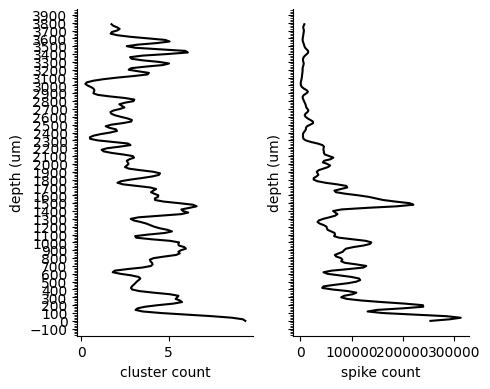

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(5, 4), sharey=True)
axs[0].plot(cluster_depth_hist, x[:-1], c='k')
axs[1].plot(cluster_spikes_depth_hist, x[:-1], c='k')

axs[0].set(ylabel='depth (um)', xlabel='cluster count')
axs[1].set(ylabel='depth (um)', xlabel='spike count')
# Remove top and right spines
axs[0].spines['top'].set_visible(False)
axs[0].spines['right'].set_visible(False)
axs[1].spines['top'].set_visible(False)
axs[1].spines['right'].set_visible(False)
# Add major ticks every 100, minor ticks every 20
axs[0].yaxis.set_major_locator(plt.MultipleLocator(100))
axs[0].yaxis.set_minor_locator(plt.MultipleLocator(20))
axs[1].yaxis.set_major_locator(plt.MultipleLocator(100))
axs[1].yaxis.set_minor_locator(plt.MultipleLocator(20))
axs[0].tick_params(axis='y', which='both', left=True)
axs[1].tick_params(axis='y', which='both', left=True)
plt.tight_layout()
plt.show()

In [6]:
def get_paths(key, subsession_id):
    # Load paths
    lfp_file = (raw_table & key & {'subsession_id': subsession_id}).fetch('lfp_path')[0]
    server = (exp_table & key).fetch1('server')
    server_local = configs.get_server_path(server, user='Bram')
    session_path = os.path.join(server_local, key['experiment_id'], "neuropixels", key['mouse_id'], key['session_id'])
    print(session_path)
    lfp_folder_path = utils.get_raw_folder_path(session_path, subsession_id)
    print(lfp_folder_path)
    meta_files = [f for f in os.listdir(lfp_folder_path) if ('ap.meta' in f) or ('lf.meta' in f)]
    if len(meta_files) == 0:
        print("No meta file found")
        lfp_folder_path = os.path.join(lfp_folder_path, os.listdir(lfp_folder_path)[0])
        meta_files = [f for f in os.listdir(lfp_folder_path) if ('ap.meta' in f) or ('lf.meta' in f)]
    meta_file = meta_files[0]
    return lfp_folder_path, lfp_file, meta_file

In [7]:
def get_CSD_vis(key, subsession_id, rec, shank, stim_type='EXPA'):
    stim_events_table = ft.event_tables.SubsessionEvents.StimEvents()
    stim_times, stim_types = (stim_events_table & key & {'subsession_id': subsession_id}).fetch1('stim_events', 'stim_types')
    stim_times = np.array(stim_times)/30000 # Convert to seconds
    stim_types = np.array(stim_types)
    stim_times = stim_times[stim_types == stim_type]
    print(len(stim_times))
    data_mat, channels, depths = depth_estimation.get_VIS_data(stim_times, rec, shank=shank) # -7s to +10s
    sf = rec.get_sampling_frequency()
    print(sf)
    # Preprocess -> Bandpass filter data 1-100Hz
    data_preproc = depth_estimation.preprocess_data(data_mat, bandpass=[1,100], sf=sf)

    # Calculate CSD
    data_preproc2, CSD = depth_estimation.calc_CSD(data_preproc)
    data_preproc2 = data_preproc2[2500*5:]
    CSD = CSD[2500*5:] # -2s to +10s

    return data_preproc2, CSD, depths, channels

def get_CSD_rfm(key, subsession_id, rec, shank):
    rfm_events_table = ft.event_tables.SubsessionEvents.RFMEvents()
    RFM_time = (rfm_events_table & key & {'subsession_id': subsession_id}).fetch1('rfm_events')#[0] # Select from 0th RFM frame (arbitrary pick)
    RFM_time = np.array(RFM_time) # Convert to numpy array
    RFM_time = RFM_time/30000 # Convert to seconds
    data_mat, channels, depths = depth_estimation.get_RFM_data(RFM_time[0], rec, shank=shank)
    sf = rec.get_sampling_frequency()
    # Preprocess -> Bandpass filter data
    data_preproc = depth_estimation.preprocess_data(data_mat, bandpass=[1,100], sf=sf)
    # Calculate CSD
    data_preproc2, CSD = depth_estimation.calc_CSD(data_preproc)
    data_preproc2 = data_preproc2[2500*5:]
    # CSD = CSD[2500*5:] # TODO:add back
    # align to rfm times
    print("CSD shape", CSD.shape)
    CSD_mat = np.zeros(shape=(90, 2500*1, CSD.shape[-1]))
    for i, rfm_time in enumerate(RFM_time[:90]):
        rfm_time -= RFM_time[0]
        print(i, rfm_time)
        CSD_mat[i] = CSD[int(rfm_time*2500):int(rfm_time*2500)+2500]
    CSD = np.mean(CSD_mat, axis=0)
    return data_preproc2, CSD, depths, channels

def plot_all_units(clusters, metrics, channels, ax, start_s=1.5, end_s=5):
    # Plot population raster plots
    clusters_stim = clusters
    start, end = 30000*start_s, 30000*end_s
    for row_i, row in metrics.iterrows():
        if row['ch'] in channels:
            # print(len(clusters_stim[0]), row_i)
            spikes = clusters_stim.get(row_i, np.array([]))
            spikes = spikes[(spikes>=start)&(spikes<=end)]-start
            ax.scatter(spikes/30000, np.ones(len(spikes))*row['depth'], marker='|', s=1, c='k', cmap='tab10', alpha=0.1)
    # ax.set(xticks=[])
    for s in ['right', 'top', 'bottom']:
        ax.spines[s].set_visible(False)
    min_depth = (1*metrics['depth']).min()
    max_depth = (1*metrics['depth']).max()

    # ax.plot([0, 0], [min_depth, min_depth+400], c='k', linewidth=3)
    ax.plot([0, 1], [min_depth-100, min_depth-100], c='k', linewidth=1)
    stim_line_y = max_depth+100
    ax.plot([0.5, (0.5+(0.85)/2)], [stim_line_y, stim_line_y], c='k', linewidth=3)
    ax.plot([0.5+0.88, (0.5+(0.88+1.7)/2)], [stim_line_y, stim_line_y], c='k', linewidth=3)
    ax.plot([0.5+1.73, (0.5+(1.73+0.425))], [stim_line_y, stim_line_y], c='k', linewidth=3)

def plot_spiking_histogram_heatmap(clusters, metrics, channels, ax, start_s=1.5, end_s=5, depth_boundaries=None):
    # Plot population raster plots
    clusters_stim = clusters
    start, end = 30000*start_s, 30000*end_s
    bin_size = 0.05 # 10ms
    bins = np.arange(start, end, bin_size*30000)
    min_depth = depth_boundaries[0] if depth_boundaries is not None else (1*metrics['depth']).min()
    max_depth = depth_boundaries[-1] if depth_boundaries is not None else (1*metrics['depth']).max()
    # min_depth = (1*metrics['depth']).min()
    # max_depth = (1*metrics['depth']).max()
    
    # depth_bins = np.arange(max_depth+15, min_depth-16, -30)
    depth_bins = np.arange(min_depth-15, max_depth+16, 30)
    spiking_histogram = np.zeros((len(depth_bins)-1, len(bins)-1))
    for row_i, row in metrics.iterrows():
        if row['ch'] in channels:
            if row['depth'] >= min_depth and row['depth'] < max_depth:
                # print(len(clusters_stim[0]), row_i)
                spikes = clusters_stim.get(row_i, np.array([]))
                spikes = spikes[(spikes>=start)&(spikes<=end)]-start
                spike_counts, _ = np.histogram(spikes, bins=bins)
                depth_idx = np.digitize(row['depth'], depth_bins)-1
                spiking_histogram[depth_idx] += spike_counts
    
    # Normalize per depth bin
    # spiking_histogram = spiking_histogram / np.max(spiking_histogram, axis=1, keepdims=True)
    # zscore based on baseline
    baseline_end = int((2-start_s)//bin_size) # 2 because trials_table has 2s baseline
    spiking_histogram = (spiking_histogram - np.mean(spiking_histogram[:,:baseline_end], axis=1, keepdims=True)) / (np.std(spiking_histogram[:,:baseline_end], axis=1, keepdims=True)+1)
    sb.heatmap(spiking_histogram, cmap='vlag', ax=ax, cbar_kws={'label': 'response (z-score)'}, center=0, vmax=np.percentile(spiking_histogram, 99.9)) # , vmax=np.percentile(spiking_histogram, 99)
    ax.set(yticks=np.arange(0, len(depth_bins)-1, 10), yticklabels=((depth_bins[:-1]+depth_bins[1:])//2).astype('int16')[::10], xticks=np.arange(0, len(bins)-1, 250), xticklabels=((bins[:-1]+bins[1:])//2/30000).astype('int16')[::250], title='Spiking histogram', ylabel='depth (um)', xlabel='time (s)')
    ax.yaxis.set_major_locator(plt.MultipleLocator(5))
    ax.yaxis.set_minor_locator(plt.MultipleLocator(1))
    # set orientation of y tick labels to horizontal
    ax.tick_params(axis='y', which='both', left=True, labelrotation=0)
    # Flip y-axis
    ax.invert_yaxis()
    

def plot_lfp_with_custom_depths(lfp_data, channel_depths, fs, max_freq=100, ax=None):
    """
    Plots a Z-scored PSD heatmap using specific channel depths.
    
    Parameters:
    - lfp_data: np.array of shape (n_samples, n_channels)
    - channel_depths: np.array or list of shape (n_channels,). 
                      Must match the order of columns in lfp_data.
    - fs: Sampling rate in Hz
    """
    
    # Validation
    n_samples, n_channels = lfp_data.shape
    if len(channel_depths) != n_channels:
        raise ValueError(f"Error: Data has {n_channels} channels, but you provided {len(channel_depths)} depth values.")

    # 1. Compute PSD
    print("Computing PSD...")
    freqs, psd = signal.welch(lfp_data, fs=fs, axis=0, nperseg=fs*2) # window of 2 seconds
    print(freqs)
    psd = psd.T  # Shape: (n_channels, n_freqs)
    
    # 2. Limit frequency range
    freq_mask = freqs <= max_freq
    plot_freqs = freqs[freq_mask]
    plot_psd = psd[:, freq_mask]
    
    # 3. Log transform and Z-score
    print("Normalizing data...")
    # plot_psd_log = 10 * np.log10(plot_psd + 1e-12)
    plot_psd_log = plot_psd
    plot_psd_norm = zscore(plot_psd_log, axis=0)
    
    # 4. Handle Depth Sorting
    # Ensure depths are sorted so the plot doesn't look scrambled if your list is out of order
    sort_idx = np.argsort(channel_depths)
    sorted_depths = np.array(channel_depths)[sort_idx]
    sorted_psd = plot_psd_norm[sort_idx, :]
    
    print(plot_freqs.shape, sorted_depths.shape, sorted_psd.shape)
    # 5. Plotting
    # plt.figure(figsize=(5, 4))
    
    # # We use pcolormesh instead of imshow because it handles non-uniform or custom axes better
    # # We create a meshgrid of Frequency (X) and Depth (Y)
    # X, Y = np.meshgrid(plot_freqs, sorted_depths)
    
    # # Use 'shading=auto' or 'nearest'
    # ax.pcolormesh(X, Y, sorted_psd, cmap='RdBu_r', vmin=-2.5, vmax=2.5, shading='auto')
    # Plot using imshow with extent
    extent = [plot_freqs[0], plot_freqs[-1], sorted_depths[0], sorted_depths[-1]]

    im = ax.imshow(sorted_psd, aspect='auto', extent=extent, origin='lower', cmap='RdBu_r', vmin=-2.5, vmax=2.5)
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Z-Scored Power (std dev)')

    # ax.colorbar(label='Z-Scored Power (std dev)')
    ax.set(xlabel='Frequency (Hz)', ylabel='Distance from tip (microns)', title='LFP Depth Profile')
    # ax.set(ylim=(depth_boundaries[0], depth_boundaries[-1]) if depth_boundaries is not None else (sorted_depths[0], sorted_depths[-1]))
    # Invert Y axis if you want 0 (deep) at the bottom and high numbers (dorsal) at top
    # Standard convention often puts deep at the bottom:
    # If your depths represent distance from tip (0=tip), use this:
    # plt.gca().invert_yaxis() 
    
    # Add Theta Guidelines
    ax.axvline(x=5, color='black', linestyle='--', alpha=0.5)
    ax.axvline(x=10, color='black', linestyle='--', alpha=0.5)
    # add colorbar
    # cbar = plt.colorbar(ax.collections[0], ax=ax)
    # cbar.set_label('Z-Scored Power (std dev)')
    # plt.tight_layout()
    # plt.show()

In [15]:
# key = {'experiment_id': '02043', 'mouse_id': '252R', 'session_id': '20230724', 'session_split': 'full'}
# key = {'experiment_id': '01826', 'mouse_id': '122R', 'session_id': '20220817', 'session_split': 'full'}

# key = (sorted_table & {'experiment_id': '02031', 'mouse_id': '258LL', 'session_id': '20230726', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02032', 'mouse_id': '265L', 'session_id': '20230724', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02042', 'mouse_id': '253LR', 'session_id': '20230725', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02043', 'mouse_id': '252R', 'session_id': '20230724', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02044', 'mouse_id': '243LL', 'session_id': '20230731', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02368', 'mouse_id': '464L', 'session_id': '20240820', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02043', 'mouse_id': '252R', 'session_id': '20230726', 'session_split': 'full'}).fetch1("KEY") # 21, 25
# key = (sorted_table & {'experiment_id': '02045', 'mouse_id': '107LR', 'session_id': '20230825', 'session_split': 'full'}).fetch1("KEY")

key = (sorted_table & {'experiment_id': '02367', 'mouse_id': '157RR', 'session_id': '20240820', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02370', 'mouse_id': '425R', 'session_id': '20240828', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02250', 'mouse_id': '380LR', 'session_id': '20240426', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02251', 'mouse_id': '379R', 'session_id': '20240514', 'session_split': 'full'}).fetch1("KEY")#0423,0426,0514
# key = (sorted_table & {'experiment_id': '02252', 'mouse_id': '386L', 'session_id': '20240506', 'session_split': 'full'}).fetch1("KEY")#0502,0506
# key = (sorted_table & {'experiment_id': '02289', 'mouse_id': '483L', 'session_id': '20240628', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02291', 'mouse_id': '485LR', 'session_id': '20240704', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02293', 'mouse_id': '487RR', 'session_id': '20240628', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02412', 'mouse_id': '610LL', 'session_id': '20250507', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02445', 'mouse_id': '616R', 'session_id': '20250527', 'session_split': 'full'}).fetch1("KEY")
# key = {'experiment_id': '02045', 'mouse_id': '107LR', 'session_id': '20230825', 'subsession_id': '03', 'session_split': 'full'}
# key = {'experiment_id': '02353', 'mouse_id': '670LR', 'session_id': '20240829', 'session_split': 'full'} # 'subsession_id': '01'
# key = {'experiment_id': '02353', 'mouse_id': '670LR', 'session_id': '20240829', 'session_split': 'full'} # 'subsession_id': '01'
# key = (sorted_table & {'experiment_id': '02356', 'mouse_id': '662L', 'session_id': '20240911', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02341', 'mouse_id': '156LL', 'session_id': '20240726', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02357', 'mouse_id': '667LR', 'session_id': '20240911', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02252', 'mouse_id': '386L', 'session_id': '20240506', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02162', 'mouse_id': '348LR', 'session_id': '20240215', 'session_split': 'full'}).fetch1("KEY") # 15, 24
# key = (sorted_table & {'experiment_id': '02357', 'mouse_id': '667LR', 'session_id': '20240909', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02357', 'mouse_id': '667LR', 'session_id': '20240909', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02161', 'mouse_id': '346L', 'session_id': '20240221', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02042', 'mouse_id': '253LR', 'session_id': '20230728', 'session_split': 'full'}).fetch1("KEY")
# key = (sorted_table & {'experiment_id': '02034', 'mouse_id': '83L', 'session_id': '20230705', 'session_split': 'full'}).fetch1("KEY")

shank = 2

stims = ['EXPA', 'SWEP_20', 'RFM']
vis_subsess_id = '01'
rfm_subsess_id = '01_RFM'

lfp_folder_path, lfp_file, meta_file = get_paths(key, vis_subsess_id)
lfp_folder_path_rfm, lfp_file_rfm, meta_file_rfm = get_paths(key, rfm_subsess_id)

S:\Data\02367\neuropixels\157RR\20240820
S:\Data\02367\neuropixels\157RR\20240820\ephys\raw\02367_157RR_20240820_01_g1
No meta file found
S:\Data\02367\neuropixels\157RR\20240820
S:\Data\02367\neuropixels\157RR\20240820\ephys\raw\02367_157RR_20240820_01_RFM_g0
No meta file found


In [16]:
rec_vis = depth_estimation.load_recording(lfp_folder_path, lfp_file, meta_file)
LFP_EXPA, CSD_EXPA, depths_EXPA, channels_EXPA = get_CSD_vis(key, vis_subsess_id, rec_vis, shank, stim_type='EXPA')
# # LFP_EXPW, CSD_EXPW, depths_EXPW, channels_EXPW = get_CSD_vis(key, vis_subsess_id, rec_vis, shank, stim_type='SWEP_4')

# rec_rfm = depth_estimation.load_recording(lfp_folder_path_rfm, lfp_file_rfm, meta_file_rfm)
# LFP_RFM, CSD_RFM, depths_RFM, channels_RFM = get_CSD_rfm(key, rfm_subsess_id, rec_rfm, shank)


10
Detected shanks: [1, 2]
(510000, 96)
30000.0


In [17]:
# LFP analysis of both shanks
lfp_folder_path_rest, lfp_file_rest, meta_file_rest = get_paths(key, '01')
rec_rest = depth_estimation.load_recording(lfp_folder_path_rest, lfp_file_rest, meta_file_rest)

channels_rest, depths_rest = depth_estimation.get_stuff(rec_rest, shank)
sf = rec_rest.get_sampling_frequency()
data_rest = rec_rest.get_traces(start_frame=int(150*sf), end_frame=int(210*sf), channel_ids=channels_rest, return_scaled=True)
# data = rec_rfm.get_traces(start_frame=int(RFM_time*sf+20*sf), end_frame=int(RFM_time*sf+80*sf), channel_ids=channels, return_scaled=True)
# Do a spectral analysis on data_mat (time x channels)
data_rest_preproc = depth_estimation.preprocess_data(data_rest, bandpass=[1,100], sf=rec_rest.get_sampling_frequency())
data_rest_preproc.shape
# data_mat, channels, depths = depth_estimation.get_RFM_data(RFM_time[0], rec_rfm, shank=shank)

S:\Data\02367\neuropixels\157RR\20240820
S:\Data\02367\neuropixels\157RR\20240820\ephys\raw\02367_157RR_20240820_01_g1
No meta file found
Detected shanks: [1, 2]


(150000, 96)

In [18]:
cluster_info, spike_clusters, cluster_metrics = (sorted_table & key).fetch1('cluster_info', 'spike_clusters', 'cluster_metrics')
# channels
shank_channel_dict = depth_estimation.get_shank_channel_dict(rec_vis)
channels_to_include = [int(ch.split('#')[1][2:]) for ch in shank_channel_dict[shank]]  # double check for NP1 signals!!!
cl_to_include = [cl for cl, ch in cluster_info['ch'].items() if (ch in channels_to_include) and (cluster_info['n_spikes'][cl]>200)] # Channel specific!
cluster_depths = np.array([cluster_info['depth'][cl] for cl in cl_to_include])
depth_num_spikes = [[cluster_info['depth'][cl]] * cluster_info['n_spikes'][cl] for cl in cl_to_include]
depth_num_spikes = np.array(depth_num_spikes)
depth_num_spikes = np.concatenate(depth_num_spikes)

# Get trial spikes
# clusters_spikes = (trials_table & key & {'subsession_id': vis_subsess_id, 'stim_type': 'EXPA'}).fetch('clusters')[0]
clusters_spikes = (subsess_spikes_table & key & {'subsession_id': '01'}).fetch('clusters')[0]
clusters_spikes_hist = (trials_table & key & {'subsession_id': vis_subsess_id, 'stim_type': 'EXPA'}).fetch('clusters', order_by='trial_id')
cluster_metrics = pd.concat([pd.DataFrame.from_dict(cluster_info), pd.DataFrame.from_dict(cluster_metrics)], axis=1)

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\ipykernel_launcher.py:8: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  


In [19]:
new_clusters_spikes = {}
for cl_key in clusters_spikes_hist[0]:
    new_clusters_spikes[cl_key] = np.concatenate([trial_spikes[cl_key] for trial_spikes in clusters_spikes_hist[:]])
clusters_spikes_hist = new_clusters_spikes

In [20]:
from scipy import ndimage
# create histogram of cluster_info['depth'] with bins of 5um
cluster_depth_sep = np.min(np.diff(np.sort(np.unique(cluster_depths)))) # 15 for np2, 20 for np1
bin_size = cluster_depth_sep*1
x = np.arange(np.min(depths_EXPA), np.max(depths_EXPA)+bin_size+1, bin_size)
print(len(x))
print(cluster_depth_sep)
cluster_depth_hist = np.histogram(cluster_depths, bins=x, density=False)[0].astype('float32')
print(len(cluster_depth_hist))
# cluster_depth_hist = cluster_depth_hist#/np.sum(cluster_depth_hist)

cluster_spikes_depth_hist = np.histogram(depth_num_spikes, bins=x, density=False)[0].astype('float32')

# Gaussian smoothing
# cluster_depth_hist = ndimage.gaussian_filter1d(cluster_depth_hist, 1)
# cluster_spikes_depth_hist = ndimage.gaussian_filter1d(cluster_spikes_depth_hist, 1)

97
15.0
96


Computing PSD...
[0.0000e+00 5.0000e-01 1.0000e+00 ... 1.2490e+03 1.2495e+03 1.2500e+03]
Normalizing data...
(201,) (96,) (96, 201)


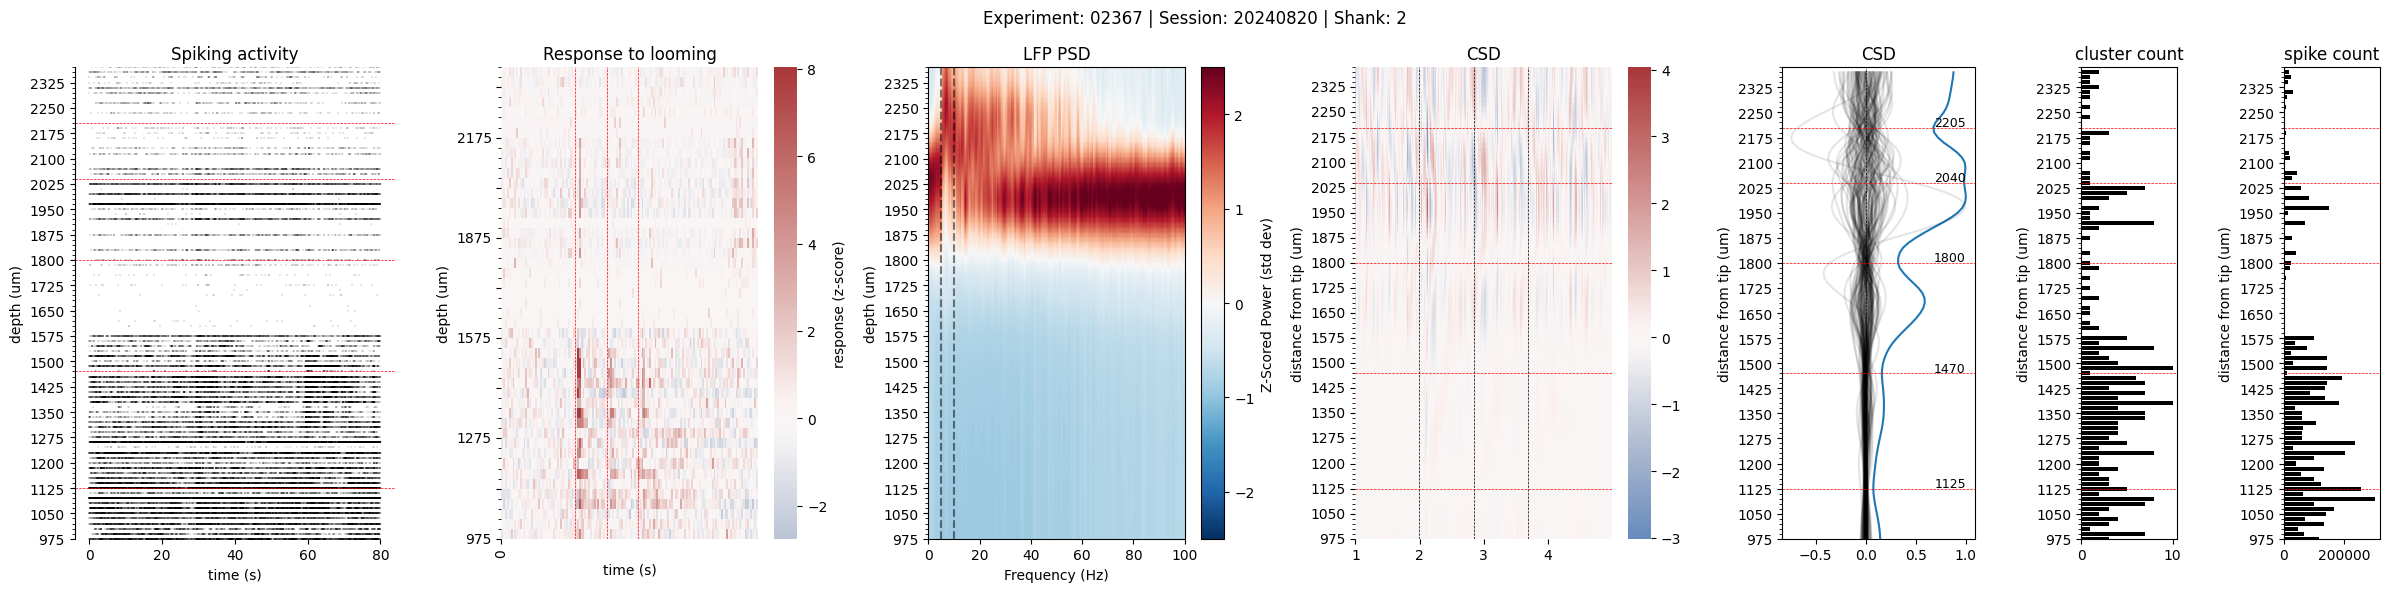

In [21]:
# Plot LFP, CSD of (EXPA ), CSD curves to decide zero crossing, and cluster count and spike count histograms
depths_fig, channels_fig = depths_EXPA[1:-1], channels_EXPA[1:-1]
# VIS
LFP_fig = LFP_EXPA[:,1:-1].T
CSD_fig = CSD_EXPA.T # -2s to +10s
# CSD_window = [int(2*2500), int(4.5*2500)]
CSD_window = [int(1*2500), int(5*2500)] # -1s to +3s

# # RFM
# LFP_fig = LFP_RFM[:,1:-1].T
# CSD_fig = CSD_RFM.T
# # CSD_window = [int(2*2500), int(5*2500)]
# CSD_window = [0, int(1*2500)]

CSD_window_size = CSD_window[1]-CSD_window[0]

# mean_CSD = np.mean(CSD_fig[:,CSD_window[0]:CSD_window[1]], axis=1)
# zero_crossings = np.where(np.diff(np.sign(mean_CSD)))[0]+1
# 
mean_CSD = np.mean(np.abs(CSD_fig[:,CSD_window[0]:CSD_window[1]]), axis=1)
from scipy.signal import find_peaks
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html
peaks = find_peaks(-mean_CSD, height=None, threshold=None, distance=3, prominence=None, width=1, wlen=None, rel_height=0.5, plateau_size=None)[0]
zero_crossings = peaks


fig = plt.figure(constrained_layout=False, figsize=(24, 3+int(7*(len(depths_fig)/192))))
gs = fig.add_gridspec(1,7, width_ratios=[1,1,1,1,0.6,0.3,0.3], height_ratios=[1])

# Axis 0: plot trial spikes
ax0 = fig.add_subplot(gs[0])
# plot_spiking_histogram_heatmap(clusters_spikes, cluster_metrics, channels_to_include, ax0, start_s=0, end_s=5)
# ax0.axvline(40, c='r', linewidth=0.5)
# ax0.axvline(40+1*0.85*20, c='r', linewidth=0.5)
# ax0.axvline(40+2*0.85*20, c='r', linewidth=0.5)

plot_all_units(clusters_spikes, cluster_metrics, channels_to_include, ax0, start_s=10, end_s=90)
# plot_all_units(clusters_spikes, cluster_metrics, channels_to_include, ax0, start_s=1, end_s=5)
# ax0.axvline(1, c='r', linewidth=0.5)
# ax0.axvline(1+1*0.85, c='r', linewidth=0.5)
# ax0.axvline(1+2*0.85, c='r', linewidth=0.5)
ax0.set(ylim=[min(depths_fig), max(depths_fig)], title='Spiking activity', ylabel='depth (um)')
# Set major ticks to be depths_fig[::5], minor ticks to be depths_fig[::1]
ax0.set_yticks(depths_fig[::5], minor=False)
ax0.set_yticklabels(depths_fig[::5].astype('int16'), minor=False)
ax0.set_yticks(depths_fig, minor=True)
ax0.set_yticklabels([], minor=True)
opto_depths, rts = (opto_cluster_table * cluster_table *cluster_depth_table & key & {'subsession_id': '01_OPTS09', 'shank': shank} & 'tagged=2' & 'median_response_time<10').fetch('depth', 'median_response_time') #  & 'median_response_time<4'
x_edge = ax0.get_xlim()[1]
if len(opto_depths)>0:
    for opto_depth, rt in zip(opto_depths, rts):
        ax0.plot(x_edge, opto_depth, 'o', c='r', markersize=5*(5/np.ceil(rt)), alpha=0.5)
    # Plot dot at opto depth on right side of plot
    # ax0.plot([ax0.get_xlim()[1]]*len(opto_depths), opto_depths, 'o', c='r', markersize=rt, alpha=0.5)
ax0.set(xlabel='time (s)')

# Axis 1: Plot LFP
ax1 = fig.add_subplot(gs[1])
plot_spiking_histogram_heatmap(clusters_spikes_hist, cluster_metrics, channels_to_include, ax1, start_s=0, end_s=7, depth_boundaries=depths_fig)
ax1.axvline(40, c='r', linewidth=0.5, linestyle='--')
ax1.axvline(40+1*0.85*20, c='r', linewidth=0.5, linestyle='--')
ax1.axvline(40+2*0.85*20, c='r', linewidth=0.5, linestyle='--')
ax1.set(title='Response to looming', ylabel='depth (um)') # ylim=[min(depths_fig)//30, max(depths_fig)//30], 
# Set major ticks to be depths_fig[::5], minor ticks to be depths_fig[::1]
# ax1.set_yticks(depths_fig[::5]//30, minor=False)
# ax1.set_yticklabels(depths_fig[::5].astype('int16'), minor=False)
# ax1.set_yticks(depths_fig//30, minor=True)
# ax1.set_yticklabels([], minor=True)
# sb.heatmap(LFP_fig[:,CSD_window[0]:CSD_window[1]], cmap='Greys', ax=ax1, center=0)
# ax1.tick_params(axis='x', labelrotation = 0)
# ax1.set(ylim=[len(channels_fig),0], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), xticks=np.arange(0, CSD_window_size, 2500)+1, xticklabels=(np.arange(0, CSD_window_size, 2500)/2500).astype('int16')+1, title='LFP', ylabel='distance from tip (um)')
# ax1.yaxis.set_major_locator(plt.MultipleLocator(5))
# ax1.yaxis.set_minor_locator(plt.MultipleLocator(1))
# ax1.tick_params(axis='y', which='both', left=True)
# ax1.invert_yaxis()

# Axis 2: Plot LFP spectral analysis
ax2 = fig.add_subplot(gs[2])
plot_lfp_with_custom_depths(data_rest_preproc, depths_rest, fs=2500, max_freq=100, ax=ax2)
ax2.set(title='LFP PSD')
ax2.set(ylim=[min(depths_fig), max(depths_fig)], ylabel='depth (um)')
# Set major ticks to be depths_fig[::5], minor ticks to be depths_fig[::1]
ax2.set_yticks(depths_fig[::5], minor=False)
ax2.set_yticklabels(depths_fig[::5].astype('int16'), minor=False)
ax2.set_yticks(depths_fig, minor=True)
ax2.set_yticklabels([], minor=True)


# Axis 3: Plot CSD
ax3 = fig.add_subplot(gs[3])
sb.heatmap(CSD_fig[:,CSD_window[0]:CSD_window[1]], cmap='vlag', ax=ax3, center=0)
ax3.set(ylim=[len(channels_fig),0], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), xticks=np.arange(0, CSD_window_size, 2500)+1, xticklabels=(np.arange(0, CSD_window_size, 2500)/2500).astype('int16')+1, title='CSD', ylabel='distance from tip (um)')
ax3.yaxis.set_major_locator(plt.MultipleLocator(5))
ax3.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax3.tick_params(axis='x', labelrotation = 0)
ax3.tick_params(axis='y', which='both', left=True)
ax3.invert_yaxis()
ax3.axvline(2500*1, c='k', linestyle='--', linewidth=0.5)
ax3.axvline(2500*(1+1*0.85), c='k', linestyle='--', linewidth=0.5)
ax3.axvline(2500*(1+2*0.85), c='k', linestyle='--', linewidth=0.5)


# Axis 4: Plot CSD mean curves
ax4 = fig.add_subplot(gs[4])
ax4.plot(mean_CSD/np.max(np.abs(mean_CSD)), channels_fig)
ax4.plot(CSD_fig[:,CSD_window[0]:CSD_window[1]][:,::100]/np.max(np.abs(CSD_fig)), channels_fig, c='k', alpha=0.1)
ax4.set(ylim=[0, len(channels_fig)], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), title='CSD', ylabel='distance from tip (um)')
ax4.yaxis.set_major_locator(plt.MultipleLocator(5))
ax4.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax4.axvline(0, linestyle='--', linewidth=0.5, c='k')

# Axis 5: Plot cluster count histogram
ax5 = fig.add_subplot(gs[5])
# ax4.plot(cluster_depth_hist[1:-1], channels_fig, c='k')
ax5.barh(channels_fig, cluster_depth_hist[1:-1], color='k')

ax5.set(ylim=[0, len(channels_fig)], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), title='CSD', ylabel='distance from tip (um)')
ax5.yaxis.set_major_locator(plt.MultipleLocator(5))
ax5.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax5.set(title='cluster count')

# Axis 6: Plot spike count histogram
ax6 = fig.add_subplot(gs[6])
# ax5.plot(cluster_spikes_depth_hist[1:-1], channels_fig, c='k')
ax6.barh(channels_fig, cluster_spikes_depth_hist[1:-1], color='k')
ax6.set(ylim=[0, len(channels_fig)], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), title='CSD', ylabel='distance from tip (um)')
ax6.yaxis.set_major_locator(plt.MultipleLocator(5))
ax6.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax6.set(title='spike count')

# # manual_crossings = [600, 810, 1260]# (optic layer: 2852-3073)]
# # for mc in manual_crossings:
# #     mc_idx = np.argmin(np.abs(depths_fig-mc))
# #     # mc_channel = (mc//cluster_depth_sep)
# #     ax0.axhline(mc, c='b', linestyle='--', linewidth=0.5)
# #     ax2.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)
# #     ax3.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)
# #     ax4.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)
# #     ax5.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)

for zc in zero_crossings:
    ax0.axhline(depths_fig[zc], c='r', linestyle='--', linewidth=0.5)
    ax3.axhline(zc, c='r', linestyle='--', linewidth=0.5)
    ax4.axhline(zc, c='r', linestyle='--', linewidth=0.5)
    # Add zero crossing depth value to the right of the horizontal line``
    ax4.text(1, zc+1, str(int(depths_fig[zc])), fontsize=9, verticalalignment='center', horizontalalignment='right')
    ax5.axhline(zc, c='r', linestyle='--', linewidth=0.5)
    ax6.axhline(zc, c='r', linestyle='--', linewidth=0.5)
plt.suptitle(f'Experiment: {key["experiment_id"]} | Session: {key["session_id"]} | Shank: {shank}')
plt.tight_layout()
# plt.savefig(rf'E:\KU Leuven\FarrowLab-Colab - VEIDB\Ephys\DepthEstimation\depth_estimation_{key["experiment_id"]}_{key["session_id"]}_shank{shank}.pdf', dpi=300)
# plt.savefig(rf'E:\KU Leuven\FarrowLab-Colab - VEIDB\Ephys\DepthEstimation\depth_estimation_{key["experiment_id"]}_{key["session_id"]}_shank{shank}.pdf', dpi=300)
plt.savefig(rf'E:\KU Leuven\FarrowLab-Colab - VEIDB\Manuscript\Figures\Ephys\raw\DepthEstimation\depth_estimation_{key["experiment_id"]}_{key["session_id"]}_shank{shank}.pdf', dpi=300)

plt.show()

In [68]:
# https://www.jneurosci.org/content/jneuro/15/1/47.full.pdf
# THETA high in DG molecular layer
# GAMMA high in DG hilus

### Populate depth table

In [79]:
exp_table = ft.Experiment()
sess_table = ft.Session()
mouse_table = ft.Mouse()
subsess_table = ft.Subsession()
raw_table = ft.ephys_tables.EphysRaw()
raw_helper_table = ft.ephys_tables.EphysRawHelper()
subsess_events_table = ft.event_tables.SubsessionEvents()
subsess_spikes_table = ft.ephys_tables.SubsessionSpikes()
sorted_table = ft.ephys_tables.SpikeSorted()
depth_table = ft.ephys_tables.SortingDepth()

In [80]:
depth_table.delete()

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\connection.py:218: UserWarning: MySQL server has gone away. Reconnecting to the server.
  warnings.warn("MySQL server has gone away. Reconnecting to the server.")


About to delete:
`DJEphys`.`__cluster_depth`: 42021 items
`DJEphys`.`sorting_depth`: 161 items
Committed.


In [98]:
database = pd.read_csv(r'E:\KU Leuven\FarrowLab-Colab - VEIDB\EphysDB_depths.csv', header=0, dtype=str, sep=',')
database = database.fillna('')

In [ ]:
02162, 02161, 02356, 02357

In [72]:
depth_table.delete()

About to delete:
`DJEphys`.`__cluster_depth`: 38795 items
`DJEphys`.`sorting_depth`: 148 items
Committed.


In [12]:
(depth_table & {'experiment_id': '02356'}).delete()

About to delete:
`DJEphys`.`sorting_depth`: 6 items
Committed.


In [ ]:
for row_idx, row in database.iterrows():
    if row['experiment_id'] == '':
        continue
    # Fix session split
    session_split = row['session_split']
    if session_split != 'full':
        # session split is a string of a number. Add a leading zero
        session_split = session_split.zfill(2)

    key = {'experiment_id': row['experiment_id'], 'mouse_id': row['mouse_id'], 'session_id': row['session_id'], 'preprocessing_type': row['preprocessing_type'], 'session_split': session_split, 'sorter_type': row['sorter_type'], 'shank': int(row['shank'])}
    key['ssc_surface'] = row['ssc_surface']
    key['ssc_bottom'] = row['ssc_bottom'] if row['ssc_bottom'] != '' else int(key['ssc_surface'])-450 # Manual sSC borders if not provided
    key['dsc_bottom'] = row['dsc_bottom'] if row['dsc_bottom'] != '' else int(key['ssc_bottom'])-800 # Manual dSC borders if not provided
    print(key)
    depth_table.insert1(key, skip_duplicates=True)

{'experiment_id': '01817', 'mouse_id': '284LL', 'session_id': '20220811', 'preprocessing_type': 'IBL', 'session_split': '01', 'sorter_type': 'KS3', 'shank': 0, 'ssc_surface': '2680', 'ssc_bottom': 2230, 'dsc_bottom': 1430}
{'experiment_id': '01817', 'mouse_id': '284LL', 'session_id': '20220811', 'preprocessing_type': 'IBL', 'session_split': '03', 'sorter_type': 'KS3', 'shank': 0, 'ssc_surface': '2820', 'ssc_bottom': 2370, 'dsc_bottom': 1570}
{'experiment_id': '02030', 'mouse_id': '255L', 'session_id': '20230720', 'preprocessing_type': 'IBL', 'session_split': 'full', 'sorter_type': 'KS3', 'shank': 1, 'ssc_surface': '2910', 'ssc_bottom': '2425', 'dsc_bottom': '1480'}
{'experiment_id': '02030', 'mouse_id': '255L', 'session_id': '20230720', 'preprocessing_type': 'IBL', 'session_split': 'full', 'sorter_type': 'KS3', 'shank': 2, 'ssc_surface': '3025', 'ssc_bottom': '2525', 'dsc_bottom': '1600'}
{'experiment_id': '02030', 'mouse_id': '255L', 'session_id': '20230723', 'preprocessing_type': 'IB

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

{'experiment_id': '01823', 'mouse_id': '120LL', 'session_id': '20220830', 'preprocessing_type': 'IBL', 'session_split': '03', 'sorter_type': 'KS3', 'shank': 0, 'ssc_surface': '3080', 'ssc_bottom': 2630, 'dsc_bottom': 1830}
{'experiment_id': '01821', 'mouse_id': '119LR', 'session_id': '20220830', 'preprocessing_type': 'IBL', 'session_split': '01', 'sorter_type': 'KS3', 'shank': 0, 'ssc_surface': '3480', 'ssc_bottom': 3030, 'dsc_bottom': 2230}
{'experiment_id': '01821', 'mouse_id': '119LR', 'session_id': '20220830', 'preprocessing_type': 'IBL', 'session_split': '03', 'sorter_type': 'KS3', 'shank': 0, 'ssc_surface': '3520', 'ssc_bottom': 3070, 'dsc_bottom': 2270}
{'experiment_id': '01850', 'mouse_id': '61LR', 'session_id': '20221214', 'preprocessing_type': 'IBL', 'session_split': '01', 'sorter_type': 'KS3', 'shank': 0, 'ssc_surface': '3350', 'ssc_bottom': 2900, 'dsc_bottom': 2100}
{'experiment_id': '01850', 'mouse_id': '61LR', 'session_id': '20221214', 'preprocessing_type': 'IBL', 'sessio

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

{'experiment_id': '02285', 'mouse_id': '498L', 'session_id': '20240619', 'preprocessing_type': 'IBL', 'session_split': 'full', 'sorter_type': 'KS3', 'shank': 1, 'ssc_surface': '3270', 'ssc_bottom': '2870', 'dsc_bottom': '2160'}
{'experiment_id': '02285', 'mouse_id': '498L', 'session_id': '20240619', 'preprocessing_type': 'IBL', 'session_split': 'full', 'sorter_type': 'KS3', 'shank': 2, 'ssc_surface': '3210', 'ssc_bottom': '2795', 'dsc_bottom': '2085'}
{'experiment_id': '02285', 'mouse_id': '498L', 'session_id': '20240621', 'preprocessing_type': 'IBL', 'session_split': 'full', 'sorter_type': 'KS3', 'shank': 1, 'ssc_surface': '3360', 'ssc_bottom': '2900', 'dsc_bottom': '2295'}
{'experiment_id': '02285', 'mouse_id': '498L', 'session_id': '20240621', 'preprocessing_type': 'IBL', 'session_split': 'full', 'sorter_type': 'KS3', 'shank': 2, 'ssc_surface': '3315', 'ssc_bottom': '2885', 'dsc_bottom': '2280'}
{'experiment_id': '02286', 'mouse_id': '499R', 'session_id': '20240619', 'preprocessing_

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

In [100]:
(depth_table & {'experiment_id': '02367', 'session_id': '20240823'})#.delete()

experiment_id,mouse_id,session_id,preprocessing_type,"session_split full, 01, 02, 03, etc.",sorter_type,shank,ssc_surface,ssc_bottom,dsc_bottom
02367,157RR,20240823,IBL,full,KS3,3,2265,1805,945


In [101]:
cluster_depth_table = ft.ephys_tables.ClusterDepth()
cluster_depth_table.populate({'experiment_id': '02367', 'session_id': '20240823'})

3 2265 0.0
3 2265 0.0


c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

3 2265 30.0
3 2265 0.0


c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

3 2265 0.0
3 2265 15.0


...

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

3 2265 2865.0
3 2265 2865.0


c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

3 2265 2850.0
3 2265 2865.0
3 2265 2865.0


c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if value is None or (attr.numeric and (value == '' or np.isnan(np.float(value)))):
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\datajoint\table.py:257: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  if 

In [ ]:
cluster_depth_table

In [ ]:
cluster_depth_table.populate({'experiment_id': '02252'})
cluster_depth_table.populate({'experiment_id': '02357'})
cluster_depth_table.populate({'experiment_id': '02356'})
cluster_depth_table.populate({'experiment_id': '02162'})
cluster_depth_table.populate({'experiment_id': '02161'})
# cluster_depth_table.populate({'experiment_id': '02252'})

In [18]:
cluster_depth_table.populate({'experiment_id': '02252'})

In [ ]:
cluster_depth_table.populate({'experiment_id': '02162'})

# AUTOMATE

In [ ]:
exp_ids = ['02042', '02043', '02044', '02045', '02047', '01764', '01826', '01823', '01821',
            '01850', '01851', '01852', '01942', '02046', '02034', '02218', '02160', '02219', 
            '02250', '02254', '02255', '02368', '02369', '02370', '02268', '02341', '02367', 
            '02285', '02286', '02289', '02290', '02291', '02292', '02293']


In [ ]:
from scipy import ndimage

stims = ['EXPA', 'SWEP_20', 'RFM']
vis_subsess_id = '01'
rfm_subsess_id = '01_RFM'

for exp_id in exp_ids:
    keys = (sorted_table & {'experiment_id': exp_id}.fetch('KEY'))
    for key in keys:
        shanks = [0,1,2,3] # or get shanks
        for shank in shanks:
            try:
                lfp_folder_path, lfp_file, meta_file = get_paths(key, vis_subsess_id)
                lfp_folder_path_rfm, lfp_file_rfm, meta_file_rfm = get_paths(key, rfm_subsess_id)
                rec_vis = depth_estimation.load_recording(lfp_folder_path, lfp_file, meta_file)
                LFP_EXPA, CSD_EXPA, depths_EXPA, channels_EXPA = get_CSD_vis(key, vis_subsess_id, rec_vis, shank, stim_type='EXPA')

                # LFP analysis of both shanks
                lfp_folder_path_rest, lfp_file_rest, meta_file_rest = get_paths(key, '01')
                rec_rest = depth_estimation.load_recording(lfp_folder_path_rest, lfp_file_rest, meta_file_rest)

                channels_rest, depths_rest = depth_estimation.get_stuff(rec_rest, shank)
                sf = rec_rest.get_sampling_frequency()
                data_rest = rec_rest.get_traces(start_frame=int(150*sf), end_frame=int(210*sf), channel_ids=channels_rest, return_scaled=True)
                # data = rec_rfm.get_traces(start_frame=int(RFM_time*sf+20*sf), end_frame=int(RFM_time*sf+80*sf), channel_ids=channels, return_scaled=True)
                # Do a spectral analysis on data_mat (time x channels)
                data_rest_preproc = depth_estimation.preprocess_data(data_rest, bandpass=[1,100], sf=rec_rest.get_sampling_frequency())
                data_rest_preproc.shape
                # data_mat, channels, depths = depth_estimation.get_RFM_data(RFM_time[0], rec_rfm, shank=shank)

                cluster_info, spike_clusters, cluster_metrics = (sorted_table & key).fetch1('cluster_info', 'spike_clusters', 'cluster_metrics')
                # channels
                shank_channel_dict = depth_estimation.get_shank_channel_dict(rec_vis)
                channels_to_include = [int(ch.split('#')[1][2:]) for ch in shank_channel_dict[shank]]  # double check for NP1 signals!!!
                cl_to_include = [cl for cl, ch in cluster_info['ch'].items() if (ch in channels_to_include) and (cluster_info['n_spikes'][cl]>200)] # Channel specific!
                cluster_depths = np.array([cluster_info['depth'][cl] for cl in cl_to_include])
                depth_num_spikes = [[cluster_info['depth'][cl]] * cluster_info['n_spikes'][cl] for cl in cl_to_include]
                depth_num_spikes = np.array(depth_num_spikes)
                depth_num_spikes = np.concatenate(depth_num_spikes)

                # Get trial spikes
                # clusters_spikes = (trials_table & key & {'subsession_id': vis_subsess_id, 'stim_type': 'EXPA'}).fetch('clusters')[0]
                clusters_spikes = (subsess_spikes_table & key & {'subsession_id': '01'}).fetch('clusters')[0]
                clusters_spikes_hist = (trials_table & key & {'subsession_id': vis_subsess_id, 'stim_type': 'EXPA'}).fetch('clusters', order_by='trial_id')
                cluster_metrics = pd.concat([pd.DataFrame.from_dict(cluster_info), pd.DataFrame.from_dict(cluster_metrics)], axis=1)

                new_clusters_spikes = {}
                for cl_key in clusters_spikes_hist[0]:
                    new_clusters_spikes[cl_key] = np.concatenate([trial_spikes[cl_key] for trial_spikes in clusters_spikes_hist[:]])
                clusters_spikes_hist = new_clusters_spikes

                # create histogram of cluster_info['depth'] with bins of 5um
                cluster_depth_sep = np.min(np.diff(np.sort(np.unique(cluster_depths)))) # 15 for np2, 20 for np1
                bin_size = cluster_depth_sep*1
                x = np.arange(np.min(depths_EXPA), np.max(depths_EXPA)+bin_size+1, bin_size)
                print(len(x))
                print(cluster_depth_sep)
                cluster_depth_hist = np.histogram(cluster_depths, bins=x, density=False)[0].astype('float32')
                print(len(cluster_depth_hist))
                # cluster_depth_hist = cluster_depth_hist#/np.sum(cluster_depth_hist)

                cluster_spikes_depth_hist = np.histogram(depth_num_spikes, bins=x, density=False)[0].astype('float32')

                # Gaussian smoothing
                # cluster_depth_hist = ndimage.gaussian_filter1d(cluster_depth_hist, 1)
                # cluster_spikes_depth_hist = ndimage.gaussian_filter1d(cluster_spikes_depth_hist, 1)

                # Plot LFP, CSD of (EXPA ), CSD curves to decide zero crossing, and cluster count and spike count histograms
                depths_fig, channels_fig = depths_EXPA[1:-1], channels_EXPA[1:-1]
                # VIS
                LFP_fig = LFP_EXPA[:,1:-1].T
                CSD_fig = CSD_EXPA.T # -2s to +10s
                # CSD_window = [int(2*2500), int(4.5*2500)]
                CSD_window = [int(1*2500), int(5*2500)] # -1s to +3s

                # # RFM
                # LFP_fig = LFP_RFM[:,1:-1].T
                # CSD_fig = CSD_RFM.T
                # # CSD_window = [int(2*2500), int(5*2500)]
                # CSD_window = [0, int(1*2500)]

                CSD_window_size = CSD_window[1]-CSD_window[0]

                # mean_CSD = np.mean(CSD_fig[:,CSD_window[0]:CSD_window[1]], axis=1)
                # zero_crossings = np.where(np.diff(np.sign(mean_CSD)))[0]+1
                # 
                mean_CSD = np.mean(np.abs(CSD_fig[:,CSD_window[0]:CSD_window[1]]), axis=1)
                from scipy.signal import find_peaks
                # https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html
                peaks = find_peaks(-mean_CSD, height=None, threshold=None, distance=3, prominence=None, width=1, wlen=None, rel_height=0.5, plateau_size=None)[0]
                zero_crossings = peaks


                fig = plt.figure(constrained_layout=False, figsize=(24, 3+int(7*(len(depths_fig)/192))))
                gs = fig.add_gridspec(1,7, width_ratios=[1,1,1,1,0.6,0.3,0.3], height_ratios=[1])

                # Axis 0: plot trial spikes
                ax0 = fig.add_subplot(gs[0])
                # plot_spiking_histogram_heatmap(clusters_spikes, cluster_metrics, channels_to_include, ax0, start_s=0, end_s=5)
                # ax0.axvline(40, c='r', linewidth=0.5)
                # ax0.axvline(40+1*0.85*20, c='r', linewidth=0.5)
                # ax0.axvline(40+2*0.85*20, c='r', linewidth=0.5)

                plot_all_units(clusters_spikes, cluster_metrics, channels_to_include, ax0, start_s=10, end_s=90)
                # plot_all_units(clusters_spikes, cluster_metrics, channels_to_include, ax0, start_s=1, end_s=5)
                # ax0.axvline(1, c='r', linewidth=0.5)
                # ax0.axvline(1+1*0.85, c='r', linewidth=0.5)
                # ax0.axvline(1+2*0.85, c='r', linewidth=0.5)
                ax0.set(ylim=[min(depths_fig), max(depths_fig)], title='Spiking activity', ylabel='depth (um)')
                # Set major ticks to be depths_fig[::5], minor ticks to be depths_fig[::1]
                ax0.set_yticks(depths_fig[::5], minor=False)
                ax0.set_yticklabels(depths_fig[::5].astype('int16'), minor=False)
                ax0.set_yticks(depths_fig, minor=True)
                ax0.set_yticklabels([], minor=True)
                opto_depths, rts = (opto_cluster_table * cluster_table *cluster_depth_table & key & {'subsession_id': '01_OPTS09', 'shank': shank} & 'tagged=2' & 'median_response_time<10').fetch('depth', 'median_response_time') #  & 'median_response_time<4'
                x_edge = ax0.get_xlim()[1]
                if len(opto_depths)>0:
                    for opto_depth, rt in zip(opto_depths, rts):
                        ax0.plot(x_edge, opto_depth, 'o', c='r', markersize=5*(5/np.ceil(rt)), alpha=0.5)
                    # Plot dot at opto depth on right side of plot
                    # ax0.plot([ax0.get_xlim()[1]]*len(opto_depths), opto_depths, 'o', c='r', markersize=rt, alpha=0.5)
                ax0.set(xlabel='time (s)')

                # Axis 1: Plot LFP
                ax1 = fig.add_subplot(gs[1])
                plot_spiking_histogram_heatmap(clusters_spikes_hist, cluster_metrics, channels_to_include, ax1, start_s=0, end_s=7, depth_boundaries=depths_fig)
                ax1.axvline(40, c='r', linewidth=0.5, linestyle='--')
                ax1.axvline(40+1*0.85*20, c='r', linewidth=0.5, linestyle='--')
                ax1.axvline(40+2*0.85*20, c='r', linewidth=0.5, linestyle='--')
                ax1.set(title='Response to looming', ylabel='depth (um)') # ylim=[min(depths_fig)//30, max(depths_fig)//30], 
                # Set major ticks to be depths_fig[::5], minor ticks to be depths_fig[::1]
                # ax1.set_yticks(depths_fig[::5]//30, minor=False)
                # ax1.set_yticklabels(depths_fig[::5].astype('int16'), minor=False)
                # ax1.set_yticks(depths_fig//30, minor=True)
                # ax1.set_yticklabels([], minor=True)
                # sb.heatmap(LFP_fig[:,CSD_window[0]:CSD_window[1]], cmap='Greys', ax=ax1, center=0)
                # ax1.tick_params(axis='x', labelrotation = 0)
                # ax1.set(ylim=[len(channels_fig),0], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), xticks=np.arange(0, CSD_window_size, 2500)+1, xticklabels=(np.arange(0, CSD_window_size, 2500)/2500).astype('int16')+1, title='LFP', ylabel='distance from tip (um)')
                # ax1.yaxis.set_major_locator(plt.MultipleLocator(5))
                # ax1.yaxis.set_minor_locator(plt.MultipleLocator(1))
                # ax1.tick_params(axis='y', which='both', left=True)
                # ax1.invert_yaxis()

                # Axis 2: Plot LFP spectral analysis
                ax2 = fig.add_subplot(gs[2])
                plot_lfp_with_custom_depths(data_rest_preproc, depths_rest, fs=2500, max_freq=100, ax=ax2)
                ax2.set(title='LFP PSD')
                ax2.set(ylim=[min(depths_fig), max(depths_fig)], ylabel='depth (um)')
                # Set major ticks to be depths_fig[::5], minor ticks to be depths_fig[::1]
                ax2.set_yticks(depths_fig[::5], minor=False)
                ax2.set_yticklabels(depths_fig[::5].astype('int16'), minor=False)
                ax2.set_yticks(depths_fig, minor=True)
                ax2.set_yticklabels([], minor=True)


                # Axis 3: Plot CSD
                ax3 = fig.add_subplot(gs[3])
                sb.heatmap(CSD_fig[:,CSD_window[0]:CSD_window[1]], cmap='vlag', ax=ax3, center=0)
                ax3.set(ylim=[len(channels_fig),0], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), xticks=np.arange(0, CSD_window_size, 2500)+1, xticklabels=(np.arange(0, CSD_window_size, 2500)/2500).astype('int16')+1, title='CSD', ylabel='distance from tip (um)')
                ax3.yaxis.set_major_locator(plt.MultipleLocator(5))
                ax3.yaxis.set_minor_locator(plt.MultipleLocator(1))
                ax3.tick_params(axis='x', labelrotation = 0)
                ax3.tick_params(axis='y', which='both', left=True)
                ax3.invert_yaxis()
                ax3.axvline(2500*1, c='k', linestyle='--', linewidth=0.5)
                ax3.axvline(2500*(1+1*0.85), c='k', linestyle='--', linewidth=0.5)
                ax3.axvline(2500*(1+2*0.85), c='k', linestyle='--', linewidth=0.5)


                # Axis 4: Plot CSD mean curves
                ax4 = fig.add_subplot(gs[4])
                ax4.plot(mean_CSD/np.max(np.abs(mean_CSD)), channels_fig)
                ax4.plot(CSD_fig[:,CSD_window[0]:CSD_window[1]][:,::100]/np.max(np.abs(CSD_fig)), channels_fig, c='k', alpha=0.1)
                ax4.set(ylim=[0, len(channels_fig)], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), title='CSD', ylabel='distance from tip (um)')
                ax4.yaxis.set_major_locator(plt.MultipleLocator(5))
                ax4.yaxis.set_minor_locator(plt.MultipleLocator(1))
                ax4.axvline(0, linestyle='--', linewidth=0.5, c='k')

                # Axis 5: Plot cluster count histogram
                ax5 = fig.add_subplot(gs[5])
                # ax4.plot(cluster_depth_hist[1:-1], channels_fig, c='k')
                ax5.barh(channels_fig, cluster_depth_hist[1:-1], color='k')

                ax5.set(ylim=[0, len(channels_fig)], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), title='CSD', ylabel='distance from tip (um)')
                ax5.yaxis.set_major_locator(plt.MultipleLocator(5))
                ax5.yaxis.set_minor_locator(plt.MultipleLocator(1))
                ax5.set(title='cluster count')

                # Axis 6: Plot spike count histogram
                ax6 = fig.add_subplot(gs[6])
                # ax5.plot(cluster_spikes_depth_hist[1:-1], channels_fig, c='k')
                ax6.barh(channels_fig, cluster_spikes_depth_hist[1:-1], color='k')
                ax6.set(ylim=[0, len(channels_fig)], yticks=np.arange(0, len(channels_fig)), yticklabels=depths_fig.astype('int16'), title='CSD', ylabel='distance from tip (um)')
                ax6.yaxis.set_major_locator(plt.MultipleLocator(5))
                ax6.yaxis.set_minor_locator(plt.MultipleLocator(1))
                ax6.set(title='spike count')

                # # manual_crossings = [600, 810, 1260]# (optic layer: 2852-3073)]
                # # for mc in manual_crossings:
                # #     mc_idx = np.argmin(np.abs(depths_fig-mc))
                # #     # mc_channel = (mc//cluster_depth_sep)
                # #     ax0.axhline(mc, c='b', linestyle='--', linewidth=0.5)
                # #     ax2.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)
                # #     ax3.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)
                # #     ax4.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)
                # #     ax5.axhline(mc_idx, c='b', linestyle='--', linewidth=0.5)

                for zc in zero_crossings:
                    ax0.axhline(depths_fig[zc], c='r', linestyle='--', linewidth=0.5)
                    ax3.axhline(zc, c='r', linestyle='--', linewidth=0.5)
                    ax4.axhline(zc, c='r', linestyle='--', linewidth=0.5)
                    # Add zero crossing depth value to the right of the horizontal line``
                    ax4.text(1, zc+1, str(int(depths_fig[zc])), fontsize=9, verticalalignment='center', horizontalalignment='right')
                    ax5.axhline(zc, c='r', linestyle='--', linewidth=0.5)
                    ax6.axhline(zc, c='r', linestyle='--', linewidth=0.5)
                plt.suptitle(f'Experiment: {key["experiment_id"]} | Session: {key["session_id"]} | Shank: {shank}')
                plt.tight_layout()
                # plt.savefig(rf'E:\KU Leuven\FarrowLab-Colab - VEIDB\Ephys\DepthEstimation\depth_estimation_{key["experiment_id"]}_{key["session_id"]}_shank{shank}.pdf', dpi=300)
                plt.savefig(rf'E:\KU Leuven\FarrowLab-Colab - VEIDB\Ephys\DepthEstimation\unchecked\depth_estimation_{key["experiment_id"]}_{key["session_id"]}_shank{shank}.png', dpi=300)
                plt.show()
            except Exception as e:
                print(f'Error processing {key}: {e}')
                